# Rendimientos financieros: de precios a rendimientos

**Autor:** David Niño  
**Área:** Finanzas cuantitativas y análisis de datos  
**Herramientas:** Python, `pandas`, `numpy` y `matplotlib`

## Objetivos de aprendizaje

Al terminar este notebook podrás:

- Calcular rendimientos simples a partir de precios.
- Entender la diferencia entre rendimiento del precio y rendimiento total.
- Calcular rendimientos acumulados mediante capitalización.
- Comparar activos usando el rendimiento promedio y la volatilidad.
- Anualizar rendimientos mensuales, trimestrales y diarios.
- Implementar estos cálculos con `pandas`, `numpy` y `matplotlib`.

**Nota sobre los datos:** los precios de este notebook son simulados, pero se han construido para representar situaciones plausibles de inversión. No corresponden a cotizaciones históricas ni deben utilizarse para tomar decisiones financieras reales.

## 1. ¿Qué es el rendimiento de una inversión?

El rendimiento mide el cambio porcentual del valor de una inversión durante un período.

Si el precio al inicio del período es $P_t$ y el precio al final es $P_{t+1}$, el rendimiento simple es:

$$
r_{t,t+1}=\frac{P_{t+1}-P_t}{P_t}
=\frac{P_{t+1}}{P_t}-1
$$

- Un rendimiento positivo indica una ganancia.
- Un rendimiento negativo indica una pérdida.
- Un rendimiento de cero indica que el precio no cambió.

### Ejemplo: una acción que sube de precio

Supongamos que una persona compra una acción por COP $\$25.000$ y al final de la semana vale COP $\$26.500$.

In [1]:
precio_inicial = 25_000
precio_final = 26_500

rendimiento = precio_final / precio_inicial - 1

print(f"Rendimiento: {rendimiento:.1%}")

Rendimiento: 6.0%


El resultado es un rendimiento del **6 %**. Por cada COP $\$25.000$ invertidos, el aumento del precio equivale a COP $\$1.500$, antes de comisiones, impuestos y otros costes.

### El formato $1+r\$

También es útil expresar el rendimiento como un factor de crecimiento:

$$
1+r=\frac{P_{t+1}}{P_t}
$$

En el ejemplo, el factor es $1.06$. Esto significa que cada peso invertido se convierte en $1,06 durante ese período, si solo consideramos el cambio de precio.

| Rendimiento | Factor \(1+r\) | Interpretación |
|---:|---:|---|
| 6 % | 1,06 | El valor aumenta un 6 % |
| 0 % | 1,00 | El valor no cambia |
| −4 % | 0,96 | El valor disminuye un 4 % |

Esta forma será especialmente útil para calcular rendimientos acumulados.

## 2. Calcular rendimientos a partir de una serie de precios

Trabajaremos con dos activos ficticios que representan inversiones diferentes:

- **Andina:** una acción ficticia de una empresa de consumo, con variaciones relativamente moderadas.
- **Cóndor:** un activo ficticio más volátil, cuyos precios fluctúan con mayor intensidad.

Los precios son simulados y están expresados en pesos colombianos (COP). Para ilustrar el cálculo, consideraremos observaciones mensuales.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

precios = pd.DataFrame(
    {
        "Andina": [25_000, 25_600, 25_200, 25_800, 26_000, 26_400,
                   26_100, 26_700, 26_500, 27_000, 27_300, 27_100, 27_600],
        "Cóndor": [40_000, 43_000, 39_500, 42_000, 38_000, 41_500,
                   44_000, 40_000, 45_000, 42_500, 37_000, 40_500, 43_000]
    },
    index=pd.date_range("2025-01-31", periods=13, freq="ME")
)

precios.index.name = "Fecha"
precios

,Andina,Cóndor
Fecha,,
2025-01-31,25000,40000
2025-02-28,25600,43000
2025-03-31,25200,39500
2025-04-30,25800,42000
2025-05-31,26000,38000
2025-06-30,26400,41500
2025-07-31,26100,44000
2025-08-31,26700,40000
2025-09-30,26500,45000


Cada fila contiene el precio observado al final de un mes. Antes de calcular rendimientos, conviene visualizar los precios para identificar tendencias generales y fluctuaciones.

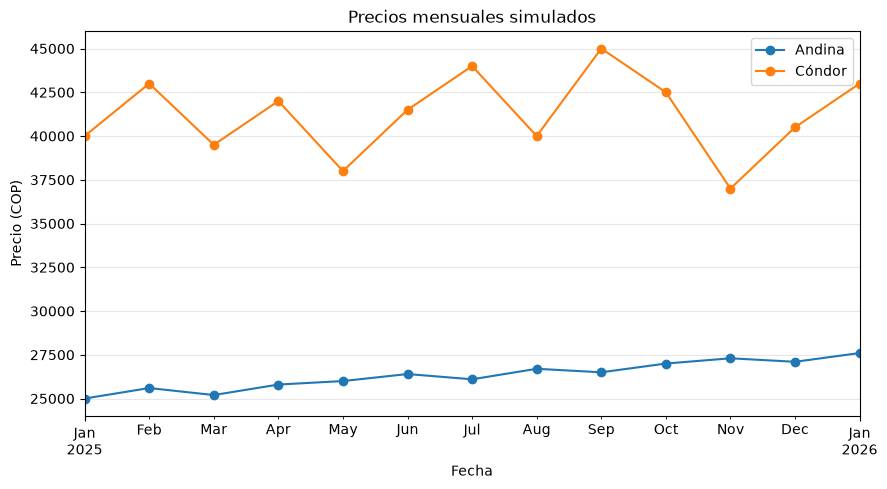

In [3]:
ax = precios.plot(figsize=(10, 5), marker="o")
ax.set_title("Precios mensuales simulados")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio (COP)")
ax.grid(alpha=0.3)
plt.show()

### Cálculo manual con NumPy

Para una serie de precios, el rendimiento entre cada par de observaciones consecutivas se calcula dividiendo cada precio por el anterior y restando uno.

En Python, una lista normal no permite dividir elemento a elemento como si fuera un vector. `NumPy` sí permite realizar esa operación.

In [4]:
precios_ejemplo = np.array([25_000, 26_500, 25_970])

rendimientos_ejemplo = precios_ejemplo[1:] / precios_ejemplo[:-1] - 1

print("Precios:", precios_ejemplo)
print("Rendimientos:", np.round(rendimientos_ejemplo, 4))
print("En porcentaje:", np.round(rendimientos_ejemplo * 100, 2))

Precios: [25000 26500 25970]
Rendimientos: [ 0.06 -0.02]
En porcentaje: [ 6. -2.]


La primera variación es de +6 % y la segunda es de −2 %. Observa que el segundo rendimiento se calcula usando como base el precio más reciente (COP $\$26.500$), no el precio inicial de COP $25.000.

### Cálculo con pandas

Con un `DataFrame`, la forma más clara suele ser `pct_change()`, que calcula el cambio porcentual respecto a la fila anterior.

In [5]:
rendimientos = precios.pct_change()

rendimientos

,Andina,Cóndor
Fecha,,
2025-01-31,NaN,NaN
2025-02-28,0.024000,0.075000
2025-03-31,-0.015625,-0.081395
2025-04-30,0.023810,0.063291
2025-05-31,0.007752,-0.095238
2025-06-30,0.015385,0.092105
2025-07-31,-0.011364,0.060241
2025-08-31,0.022989,-0.090909
2025-09-30,-0.007491,0.125000


La primera fila aparece como `NaN` porque no hay un precio anterior con el cual comparar el primer dato. Al convertir precios en rendimientos, normalmente se pierde una observación.

También podríamos escribir el cálculo usando `shift(1)`, que desplaza los precios una fila hacia abajo:

In [6]:
rendimientos_con_shift = precios / precios.shift(1) - 1
rendimientos_con_shift

,Andina,Cóndor
Fecha,,
2025-01-31,NaN,NaN
2025-02-28,0.024000,0.075000
2025-03-31,-0.015625,-0.081395
2025-04-30,0.023810,0.063291
2025-05-31,0.007752,-0.095238
2025-06-30,0.015385,0.092105
2025-07-31,-0.011364,0.060241
2025-08-31,0.022989,-0.090909
2025-09-30,-0.007491,0.125000


In [7]:
# Comprobamos que los dos métodos dan el mismo resultado.
pd.testing.assert_frame_equal(rendimientos, rendimientos_con_shift)

## 3. Rendimiento del precio y rendimiento total

Una inversión puede generar valor de dos formas: porque aumenta su precio y porque paga distribuciones, como los dividendos de una acción.

- **Rendimiento del precio:** solo considera el cambio en el precio.
- **Rendimiento total:** considera el cambio en el precio y los dividendos recibidos, suponiendo que estos se contabilizan en el período.

Una fórmula sencilla para el rendimiento total de un período es:

$$
r_t=\frac{P_{t+1}+D_{t+1}-P_t}{P_t}
$$

donde $D_{t+1}$ son los dividendos recibidos durante el período.

### Ejemplo con una acción ficticia

Una acción pasa de COP $\$50.000$ a COP $\$51.500$ y paga un dividendo de COP $\$1.000$ por acción durante el período.

In [8]:
precio_inicial = 50_000
precio_final = 51_500
dividendo = 1_000

rendimiento_precio = precio_final / precio_inicial - 1
rendimiento_total = (precio_final + dividendo) / precio_inicial - 1

print(f"Rendimiento del precio: {rendimiento_precio:.1%}")
print(f"Rendimiento total:      {rendimiento_total:.1%}")

Rendimiento del precio: 3.0%
Rendimiento total:      5.0%


El rendimiento del precio es del 3 %, mientras que el rendimiento total es del 5 %. La diferencia se debe al dividendo.

Al comparar fondos o índices bursátiles, es importante verificar si la serie de datos representa rendimientos de precio o rendimientos totales. Si el objetivo es medir el retorno incluyendo dividendos, se necesita una serie que los incorpore adecuadamente.

## 4. Rendimiento promedio y volatilidad

El promedio resume el rendimiento típico por período, pero no describe por sí solo cuánto fluctúan los rendimientos.

Comparemos dos inversiones simuladas con un rendimiento mensual promedio parecido, pero con distinta volatilidad. En este ejemplo, los datos son rendimientos mensuales hipotéticos.

In [9]:
comparacion = pd.DataFrame({
    "Estable": [0.012, 0.008, 0.010, 0.011, 0.009, 0.013,
                0.007, 0.011, 0.010, 0.009, 0.012, 0.008],
    "Volátil": [0.060, -0.035, 0.025, 0.045, -0.040, 0.055,
                -0.020, 0.035, 0.010, -0.050, 0.065, -0.030]
})

resumen = pd.DataFrame({
    "Rendimiento mensual promedio": comparacion.mean(),
    "Volatilidad mensual (desv. estándar)": comparacion.std()
})

resumen.style.format("{:.2%}")

,Rendimiento mensual promedio,Volatilidad mensual (desv. estándar)
Estable,1.00%,0.19%
Volátil,1.00%,4.29%


La desviación estándar de los rendimientos se utiliza con frecuencia como medida de volatilidad. Una desviación estándar mayor indica que los rendimientos se dispersan más alrededor de su promedio.

La volatilidad no es una descripción completa del riesgo: por ejemplo, no distingue por sí sola entre fluctuaciones al alza y a la baja, ni resume todos los riesgos de pérdida. Sin embargo, es un punto de partida útil para comparar el comportamiento de dos series.

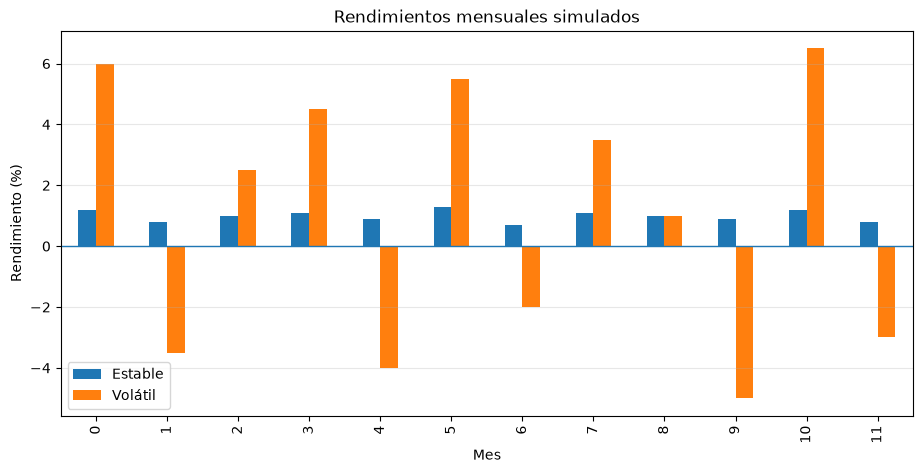

In [10]:
ax = (comparacion * 100).plot(kind="bar", figsize=(11, 5))
ax.set_title("Rendimientos mensuales simulados")
ax.set_xlabel("Mes")
ax.set_ylabel("Rendimiento (%)")
ax.axhline(0, linewidth=1)
ax.grid(axis="y", alpha=0.3)
plt.show()

### ¿Por qué el mismo promedio no garantiza el mismo resultado final?

Porque los rendimientos se acumulan multiplicativamente. Una serie puede tener un promedio aritmético similar a otra, pero terminar con un capital diferente debido a la secuencia y magnitud de sus ganancias y pérdidas.

Por eso conviene examinar tanto los rendimientos por período como el rendimiento acumulado.

## 5. Capitalización: combinar rendimientos de varios períodos

Si un capital obtiene rendimientos $r_1, r_2, \ldots, r_T$, el rendimiento acumulado es:

$$
R_{\text{acumulado}}=\prod_{t=1}^{T}(1+r_t)-1
$$

El producto de los factores $1+r_t$ da el factor de crecimiento total. Restar uno lo convierte nuevamente en rendimiento.

### Ejemplo: una inversión que gana y después pierde

Supongamos que una inversión de COP $\$2.000.000$ gana un 10 % el primer mes y pierde un 3 % el segundo mes.

In [11]:
capital_inicial = 2_000_000
rendimientos_dos_meses = pd.Series([0.10, -0.03], index=["Mes 1", "Mes 2"])

factores = 1 + rendimientos_dos_meses
capital_por_mes = capital_inicial * factores.cumprod()
rendimiento_acumulado = factores.prod() - 1

print("Factores de crecimiento:")
display(factores)

print("Capital al final de cada mes:")
display(capital_por_mes.map(lambda x: f"COP ${x:,.0f}"))

print(f"Rendimiento acumulado: {rendimiento_acumulado:.2%}")

Factores de crecimiento:


Mes 1    1.10
Mes 2    0.97
dtype: float64

Capital al final de cada mes:


Mes 1    COP $2,200,000
Mes 2    COP $2,134,000
dtype: str

Rendimiento acumulado: 6.70%


El rendimiento acumulado es del 6,7 %, no del 7 %. La segunda variación se aplica sobre el capital que quedó después del primer mes.

### Capitalización para los dos activos del ejemplo

Ahora calcularemos el rendimiento acumulado de Andina y Cóndor a partir de los rendimientos obtenidos de los precios simulados.

In [12]:
rendimiento_acumulado = (1 + rendimientos).prod() - 1
rendimiento_acumulado.map(lambda x: f"{x:.2%}")

Andina    10.40%
Cóndor     7.50%
dtype: str

Podemos verificar el mismo resultado comparando directamente el primer y el último precio, ya que en este ejemplo no se incluyen dividendos ni aportes o retiros de capital.

In [13]:
verificacion = precios.iloc[-1] / precios.iloc[0] - 1

pd.DataFrame({
    "Acumulado a partir de rendimientos": rendimiento_acumulado,
    "Cambio entre precio inicial y final": verificacion
}).style.format("{:.2%}")

,Acumulado a partir de rendimientos,Cambio entre precio inicial y final
Andina,10.40%,10.40%
Cóndor,7.50%,7.50%


### Visualizar la evolución de una inversión

Supongamos que se invierten COP $1.000.000 en cada activo al inicio y no se hacen aportes ni retiros. La evolución del capital se obtiene multiplicando el capital inicial por el producto acumulado de los factores de rendimiento.

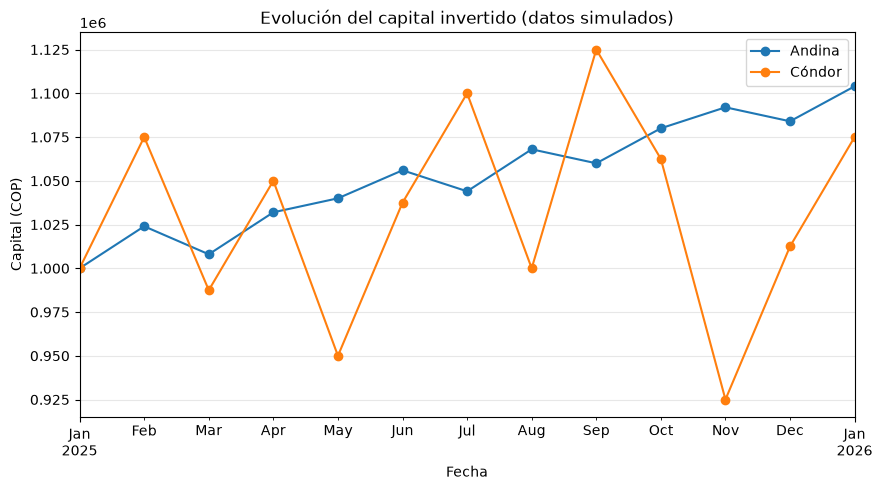

In [14]:
capital_inicial = 1_000_000
factores = 1 + rendimientos
capital = capital_inicial * factores.fillna(1).cumprod()

ax = capital.plot(figsize=(10, 5), marker="o")
ax.set_title("Evolución del capital invertido (datos simulados)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Capital (COP)")
ax.grid(alpha=0.3)
plt.show()

## 6. Anualizar rendimientos

La anualización expresa un rendimiento periódico como una tasa anual equivalente, bajo el supuesto de que el mismo rendimiento se repite en cada período.

Si $r_p$ es el rendimiento por período y hay $m$ períodos en un año:

$$
R_{\text{anualizado}}=(1+r_p)^m-1
$$

Ejemplos habituales:

- Mensual: $m=12$.
- Trimestral: $m=4$.
- Diario de mercado: suele usarse $m=252$ sesiones bursátiles, no 365 días calendario.

### Ejemplo con diferentes frecuencias

In [15]:
rendimiento_mensual = 0.01
rendimiento_trimestral = 0.04
rendimiento_diario = 0.0001

anualizado_mensual = (1 + rendimiento_mensual) ** 12 - 1
anualizado_trimestral = (1 + rendimiento_trimestral) ** 4 - 1
anualizado_diario = (1 + rendimiento_diario) ** 252 - 1

print(f"1 % mensual anualizado:       {anualizado_mensual:.2%}")
print(f"4 % trimestral anualizado:    {anualizado_trimestral:.2%}")
print(f"0,01 % diario anualizado:     {anualizado_diario:.2%}")

1 % mensual anualizado:       12.68%
4 % trimestral anualizado:    16.99%
0,01 % diario anualizado:     2.55%


La anualización no es una predicción. Es una equivalencia matemática que depende de un supuesto: que el rendimiento por período se mantiene constante. Los rendimientos reales cambian, y la tasa anualizada observada puede diferir mucho del rendimiento que finalmente se obtenga.

Además, para series con rendimientos variables, no debe confundirse la anualización de un rendimiento promedio mensual con el rendimiento anual compuesto efectivamente observado.

## 7. Leer datos desde un archivo CSV

En un análisis real, los precios suelen venir de un archivo descargado de una fuente de datos. `pandas.read_csv()` permite leer un CSV.

El siguiente ejemplo supone que existe un archivo `precios.csv` con una columna `Fecha` y columnas de precios para cada activo.

In [16]:
# Ejemplo de lectura de datos propios:
# precios_csv = pd.read_csv("precios.csv", index_col="Fecha", parse_dates=True)
# rendimientos_csv = precios_csv.pct_change()
# rendimientos_csv.head()

Antes de analizar datos financieros reales, verifica:

1. **Frecuencia:** diaria, semanal, mensual, etc.
2. **Precios ajustados:** para rendimientos totales, busca datos que incorporen dividendos y eventos corporativos cuando corresponda.
3. **Fechas y datos faltantes:** revisa observaciones duplicadas, ausencias y cambios de frecuencia.
4. **Moneda y costes:** ten en cuenta la moneda de cotización, comisiones, impuestos y, si aplica, el tipo de cambio.
5. **Interpretación:** los resultados históricos no garantizan rendimientos futuros.

## 8. Resumen

| Concepto | Cálculo | Interpretación |
|---|---|---|
| Rendimiento simple | $P_{t+1}/P_t-1$ | Cambio porcentual entre dos precios |
| Factor de crecimiento | $1+r_t$ | Multiplicador aplicado al capital |
| Rendimiento total | Cambio de precio + dividendos, relativo al precio inicial | Incluye ingresos por dividendos |
| Rendimiento acumulado | $\prod_t(1+r_t)-1$ | Cambio total tras varios períodos |
| Volatilidad | Desviación estándar de los rendimientos | Dispersión de los rendimientos |
| Rendimiento anualizado | $(1+r_p)^m-1$ | Equivalencia anual bajo un supuesto de tasa constante |

## Referencias

Luenberger, D. G. (2014). *Investment science* (2nd ed.). Oxford University Press.